In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from typing import Optional, Tuple
from dualwcfm import (
    Strategy,
    BidirectionalStrategy,
    Trainer,
    ImplicitCFMLoss,
    ConditionalFlowMatching,
    TrainingConfig,
    FeedForwardConfig,
    Visualizer,
    Visualizer3D,
    VisualizerImage,
    VisualizeConfig,
)
from dualwcfm.distributions import (
    CouplingDistribution,
    RotatedShapeCoupling,
    Simple2DGaussianDistribution,
    RotatedDistribution,
    MoonDistribution,
    SphereDistribution,
    MarginalDistribution
)
from dualwcfm.models.unet import UNetModel
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class unet_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, t, x=None, inp3=None, *args, **kwargs):
        if inp3 is not None and x is not None:
            return self.model(t, torch.cat([x, inp3], dim=1))
        if x is not None:
            return self.model(t, x)
        else:
            return self.model(t, torch.zeros_like(t))

class torch_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
        if inp3 is not None and inp2 is not None:
            return self.model(torch.cat([inp2, inp3, inp1], dim=1))
        if inp2 is not None:
            return self.model(torch.cat([inp2, inp1], dim=1))
        else:
            return self.model(inp1)

c:\Users\Antoine\AppData\Local\Programs\Python\Python39\lib\site-packages\cupy\_environment.py:216: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [3]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import numpy as np

class ImageSampler:
    """Helper to turn a DataLoader into an infinite sampler."""

    def __init__(self, dataset, batch_size, device):
        self.loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=True)
        self.iterator = iter(self.loader)
        self.device = device

    def get_batch(self, n):
        try:
            batch, _ = next(self.iterator)
        except StopIteration:
            self.iterator = iter(self.loader)
            batch, _ = next(self.iterator)
        return batch[:n].to(self.device)

class FlipCoupling(CouplingDistribution):

    def __init__(self, dataset, batch_size=32, device: Optional[torch.device] = None, perturbation_fn=None):
        self.device = device if device is not None else torch.device("cpu")
        self.sampler = ImageSampler(dataset, batch_size, self.device)
        self.perturbation_fn = perturbation_fn

    def coupling_sample(self, n: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.sampler.get_batch(n)
        y = torch.flip(x, dims=[2])
        if self.perturbation_fn is not None:
            x, y = self.perturbation_fn(x, y)
        return x, y

    def sample(self, n: int) -> torch.Tensor:
        raise NotImplementedError

    def sample_init(self, n: int) -> torch.Tensor:
        if self.perturbation_fn is not None:
            x, _ = self.perturbation_fn(self.sampler.get_batch(n), None)
            return x
        return self.sampler.get_batch(n)

    def sample_target(self, n: int) -> torch.Tensor:
        if self.perturbation_fn is not None:
            _, y = self.perturbation_fn(None, self.sampler.get_batch(n))
            return y
        return torch.flip(self.sampler.get_batch(n), dims=[2])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_image = False

if use_image:
    batch_size = 128
    tf = T.Compose([T.Resize(32), T.ToTensor(), T.Normalize((0.5,), (0.5,))])

    # ds_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)
    # ds_fashion = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tf)

    # print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    # subset_size = 10000

    # # 3. Create random indices and wrap in a Subset
    # mnist_indices = np.random.choice(len(ds_mnist), subset_size, replace=False)
    # fashion_indices = np.random.choice(len(ds_fashion), subset_size, replace=False)

    # ds_mnist = Subset(ds_mnist, mnist_indices)
    # ds_fashion = Subset(ds_fashion, fashion_indices)

    def small_rotation(x, y):
        # Apply a rotation transform to the images in x and y
        angle = 10  # degrees
        rotation = T.RandomRotation((angle, angle), fill=(-1,))
        if y is not None:
            y_rotated = rotation(y)
            return x, y_rotated
        else:
            return x, y

    # Load mnist and split it in half
    ds_mnist_full = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)

    mnist_half_size = len(ds_mnist_full) // 2
    ds1 = Subset(ds_mnist_full, list(range(mnist_half_size)))
    ds2 = Subset(ds_mnist_full, list(range(mnist_half_size, len(ds_mnist_full))))

    print(f"MNIST size: {len(ds1)}, MNIST size: {len(ds2)}")

    coupling = FlipCoupling(dataset=ds1, batch_size=batch_size, device=device)
    new_coupling_dist = FlipCoupling(dataset=ds2, batch_size=batch_size, device=device, perturbation_fn=small_rotation)
    new_source = MarginalDistribution(new_coupling_dist.sample_init)
    new_target = MarginalDistribution(new_coupling_dist.sample_target)

else:
    batch_size = 4096*2
    def anticorrelate(n: int):
        source_samples = torch.randn(n, 2) * 0.5
        # perturbation is a translation of [0.25, 0.25]
        perturbation = torch.tensor([0, 0.0])
        return source_samples, -source_samples + perturbation


    coupling = FunctionalCouplingDistribution(anticorrelate)
    source, target = coupling.get_marginals()
    loc = 2.0
    perturbation = 0.0
    new_source = Simple2DGaussianDistribution(mean=torch.tensor([loc, loc]), std=torch.tensor([0.5, 0.5]))
    new_target = Simple2DGaussianDistribution(mean=torch.tensor([-loc, -loc + perturbation]), std=torch.tensor([0.5, 0.5]))

    def new_transport_map(x):
        # Compute the perturbed transport map from new_source to new_target
        A_coup = torch.tensor([[-1.0, 0.0], [0.0, -1.0]])
        b_shift = torch.tensor([0.0, +perturbation])
        return x @ A_coup.T + b_shift

Mean of source samples in x dimension: 0.0011878673685714602, Mean of source samples in y dimension: -0.0004799931193701923
Mean of target samples in x dimension: -0.0011878673685714602, Mean of target samples in y dimension: 0.0004799931193701923
Mean of new source samples in x dimension: 2.001279830932617, Mean of new source samples in y dimension: 2.016594886779785
Mean of new target samples in x dimension: -2.012922525405884, Mean of new target samples in y dimension: -1.9889992475509644


<Figure size 800x800 with 0 Axes>

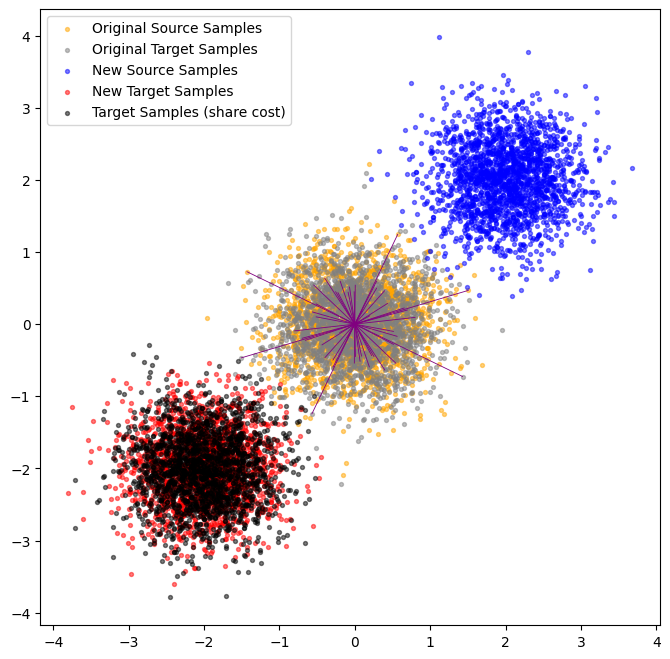

In [4]:
# import math
# theta = math.pi*2 / 3  # 60 degrees
# R = torch.tensor([[math.cos(theta), -math.sin(theta)],
#                   [math.sin(theta),  math.cos(theta)]], dtype=torch.float32)

# s1, s2 = 2.0, 0.5
# D = torch.diag(torch.tensor([s1, s2], dtype=torch.float32))

# A_coup = R @ D  # (2,2)
# b_shift = torch.tensor([-4.0, 0.0], dtype=torch.float32)  # (2,)
# b_shift_new = torch.tensor([-6.0, 1.0], dtype=torch.float32)

# def linear_coupling(n: int):
#     x = torch.randn(n, 2)
#     y = x @ A_coup.T + b_shift
#     return x, y

# def transport_map(x: torch.Tensor):
#     return x @ A_coup.T + b_shift

# class FunctionalDistribution:
#     def __init__(self, sampler_fn):
#         self.sampler_fn = sampler_fn
#     def sample(self, n):
#         return self.sampler_fn(n)

# coupling = FunctionalCouplingDistribution(linear_coupling)
# source, target = coupling.get_marginals()

# new_source = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([0.25, 0.25]))

# m_prime = torch.tensor([5.0, 5.0], dtype=torch.float32)
# Sigma_mu_prime = (0.25 ** 2) * torch.eye(2, dtype=torch.float32)  # 0.0625 I

# mean_nu_prime = A_coup @ m_prime + b_shift_new
# cov_nu_prime  = A_coup @ Sigma_mu_prime @ A_coup.T
# mean_nu_prime = mean_nu_prime.detach()
# cov_nu_prime  = cov_nu_prime.detach()
# def sample_gaussian_with_cov(n: int, mean: torch.Tensor, cov: torch.Tensor):
#     mean = mean.cpu()
#     cov  = cov.cpu()
#     L = torch.linalg.cholesky(cov)
#     z = torch.randn(n, 2)          # CPU
#     return mean + z @ L.T          # CPU


# def nu_prime_sampler(n: int):
#     mean = mean_nu_prime
#     cov  = cov_nu_prime
#     return sample_gaussian_with_cov(n, mean, cov)

# def new_transport_map(x: torch.Tensor):
#     # Compute the new transport map with nu_prime's mean and covariance
#     mean = mean_nu_prime
#     cov  = cov_nu_prime
#     L = torch.linalg.cholesky(cov)
#     return x @ L.T + mean

# new_target = FunctionalDistribution(nu_prime_sampler)  # ✅ 用函数分布表示 nu'

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 8))
n_samples = 2000
coupling_samples = coupling.coupling_sample(n_samples)
source_samples = coupling_samples[0].cpu().numpy()
target_samples = coupling_samples[1].cpu().numpy()
new_source_samples = new_source.sample(n_samples).cpu().numpy()
new_target_samples = new_target.sample(n_samples).cpu().numpy()
# true_target_samples = new_source_samples @ A_coup.T.cpu().numpy() + b_shift.cpu().numpy()
non_perturbed_target_samples = Simple2DGaussianDistribution(mean=torch.tensor([-loc, -loc]), std=torch.tensor([0.5, 0.5])).sample(n_samples).cpu().numpy()

print(f"Mean of source samples in x dimension: {source_samples[:, 0].mean()}, Mean of source samples in y dimension: {source_samples[:, 1].mean()}")
print(f"Mean of target samples in x dimension: {target_samples[:, 0].mean()}, Mean of target samples in y dimension: {target_samples[:, 1].mean()}")
print(f"Mean of new source samples in x dimension: {new_source_samples[:, 0].mean()}, Mean of new source samples in y dimension: {new_source_samples[:, 1].mean()}")
print(f"Mean of new target samples in x dimension: {new_target_samples[:, 0].mean()}, Mean of new target samples in y dimension: {new_target_samples[:, 1].mean()}")

fig = plt.figure(figsize=(8, 8))
plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
plt.scatter(non_perturbed_target_samples[:, 0], non_perturbed_target_samples[:, 1], c='black', s=8, alpha=0.5, label='Target Samples (share cost)')
plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6)
plt.legend()
plt.show()

In [5]:
class BidirectionalUnetStrategy(BidirectionalStrategy):
    # UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True).to(device)
    def _create_models(self, dim: int, hidden_size: int):
        wrapper = self.wrapper
        self.mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.f_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))
        self.g_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))

        self.forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

        self.initial_mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

In [6]:
training_config = TrainingConfig(
    device=device,
    iterations=50,
    dataset_size=200000,
    marginal_epochs=5000,
    pretrain_epochs=10000,
    dual_epochs = 100,
    cfm_epochs = 500,
    advance_steps=100,
    correction_epochs=2000,
    correction_each=10,
    l2_reg=0,
    lip_reg=0.0,
    mean_reg=0.1,
    sigma=0.1,
    sigma2=0.1,
    batch_size=batch_size,
    advance_with_flow=False,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
    loss='weighted',
    use_amp=False
)
small_training_config = TrainingConfig(
    device=device, iterations=200, batch_size=batch_size,
    dataset_size=1000,
    marginal_epochs=50, pretrain_epochs=50, dual_epochs=5, cfm_epochs=5,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
)
model_config = FeedForwardConfig(
    dimension=2,
    hidden_size=128,
    dual_learning_rate=1e-3,
    flow_learning_rate=1e-3,
    # mu_learning_rate=6e-4,
    # nu_learning_rate=6e-4
)

flow_matching = ConditionalFlowMatching()
viz_config = VisualizeConfig(show_each=10, show_each_marginal=1000, show_each_pretrain=1000)
if use_image:
    strategy = BidirectionalUnetStrategy(unet_wrapper, model_config)
    visualizer = VisualizerImage(viz_config, img_shape=(1, 32, 32))
else:
    # strategy = BidirectionalStrategy(torch_wrapper, model_config)
    strategy = Strategy(torch_wrapper, model_config)
    visualizer = Visualizer(viz_config, transport_map=new_transport_map)

trainer = Trainer(
    coupling, new_source, new_target,
    flow_matching, strategy, visualizer,
    training_config, device
)

Using disk-based coupling distribution for memory efficiency.
Initializing disk coupling at experiments/coupling_data with 25 chunks...
Disk coupling initialized: 200000 samples in 25 chunks


Skipping marginal flow matching retraining.
Loading initial marginal flow models.
Pretrained models loaded.


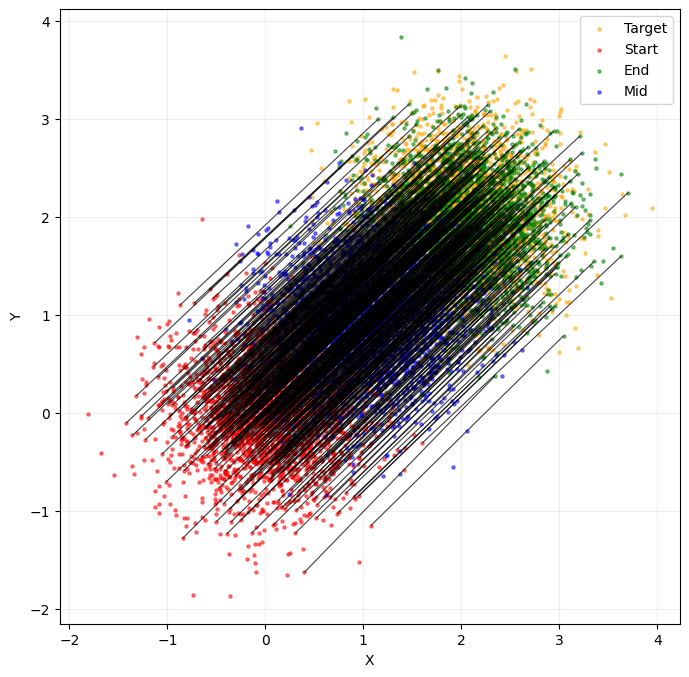

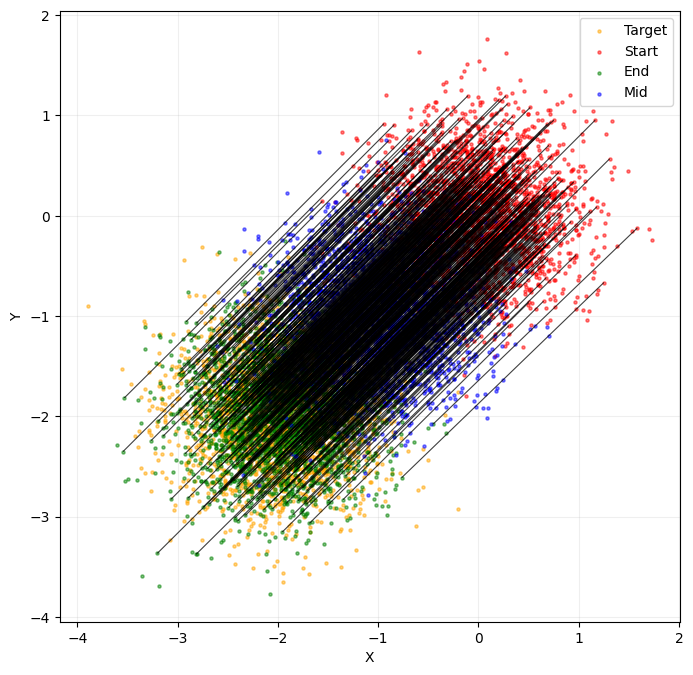

Pretraining unidirectional flow.
Skipping pretraining.
Loading initial flow model.
Pretrained models loaded.


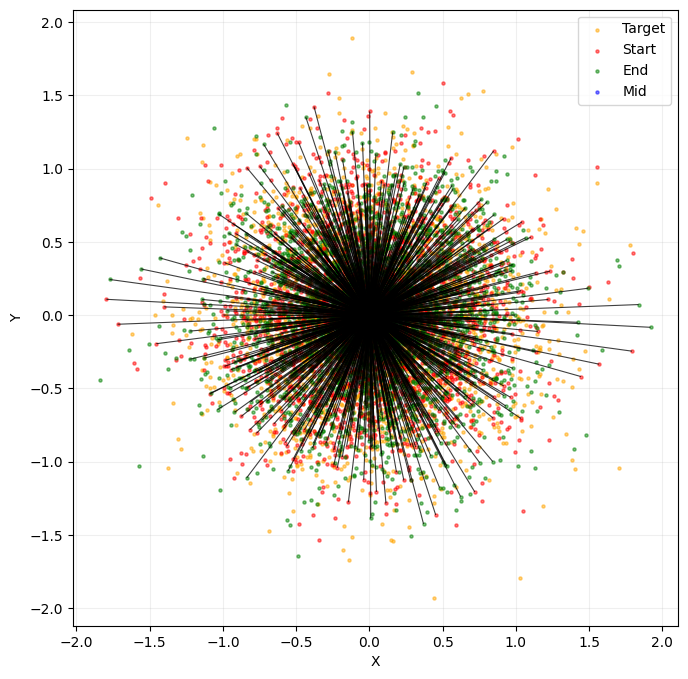

Is bidirectional? False
Iteration 1/50


Dual Training:   0%|          | 0/100 [00:00<?, ?it/s]

Last correction time: 0.0
Current time: 0.0


c:\Users\Antoine\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


   f_dual(x0) mean: 0.0779, std: 0.1181
   g_dual(x1) mean: -0.2348, std: 0.1894
   sum mean: -0.1568, std:0.0914, ex: tensor([[-0.3000],
        [-0.1512],
        [-0.2073],
        [ 0.0545],
        [-0.1707]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:03<00:00, 28.20it/s, Dual Loss=-15.6]


   f_dual(x0) mean: -0.0037, std: 2.7385
   g_dual(x1) mean: -0.0557, std: 2.9354
   sum mean: -0.0594, std:5.6485, ex: tensor([[ 2.7827],
        [ 4.5892],
        [ 0.6007],
        [-7.9991],
        [ 5.9374]], device='cuda:0')


CFM Training:   2%|▏         | 10/500 [00:00<00:05, 93.71it/s, CFM Loss=0.0128]

   Flow model output mean: 0.0021, std: 0.7117


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 111.33it/s, CFM Loss=0.00841]


   Flow model output mean: 0.0020, std: 0.7135


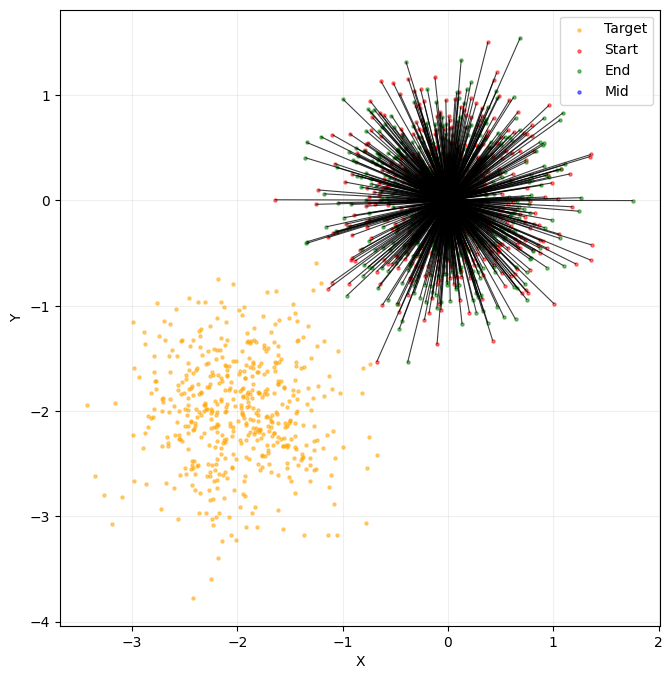

0.0078009674325585365
tensor([[ 0.0016, -0.0036],
        [ 0.0041, -0.0118],
        [ 0.0019, -0.0056],
        [ 0.0007, -0.0056],
        [-0.0006, -0.0076],
        [-0.0253, -0.0051],
        [ 0.0021,  0.0022],
        [ 0.0109, -0.0049],
        [-0.0033,  0.0011],
        [ 0.0036, -0.0161]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 27.49it/s]


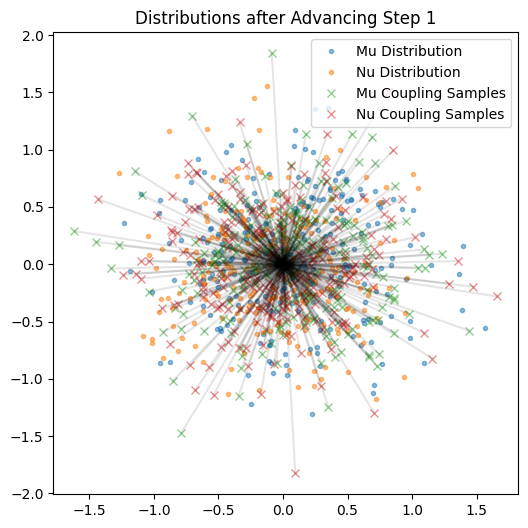

  SW distances — W1_mu=0.0313  W2_mu=0.0415  W1_nu=0.0354  W2_nu=0.0431
Iteration 2/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 35.70it/s, Dual Loss=-16.6]

Last correction time: 0.0
Current time: 0.02
   f_dual(x0) mean: 0.4247, std: 2.6605
   g_dual(x1) mean: 0.3966, std: 2.8685
   sum mean: 0.8214, std:5.5050, ex: tensor([[ 2.9778],
        [-1.3645],
        [ 7.7513],
        [-8.6683],
        [ 2.7509]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 34.20it/s, Dual Loss=-17.6]


   f_dual(x0) mean: 0.0344, std: 3.1361
   g_dual(x1) mean: -0.0525, std: 3.1622
   sum mean: -0.0181, std:5.8014, ex: tensor([[-2.6271],
        [ 7.7262],
        [ 5.8911],
        [ 0.8019],
        [ 5.3909]], device='cuda:0')


CFM Training:   1%|▏         | 7/500 [00:00<00:07, 69.03it/s, CFM Loss=0.00888]

   Flow model output mean: -0.0449, std: 0.7050


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 109.41it/s, CFM Loss=0.00837]


   Flow model output mean: -0.0382, std: 0.7071
0.013626394793391228
tensor([[ 6.4689e-03, -1.6580e-03],
        [ 3.0398e-03, -1.0335e-03],
        [ 2.3797e-02,  2.1860e-03],
        [-8.8096e-05,  6.3603e-03],
        [ 1.1540e-02, -1.3820e-03],
        [ 1.4806e-02, -4.4762e-03],
        [ 2.7616e-02, -6.6186e-03],
        [ 7.3328e-03,  4.8380e-03],
        [ 6.2056e-03, -1.2942e-02],
        [ 1.8196e-02, -9.3493e-04]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.70it/s]


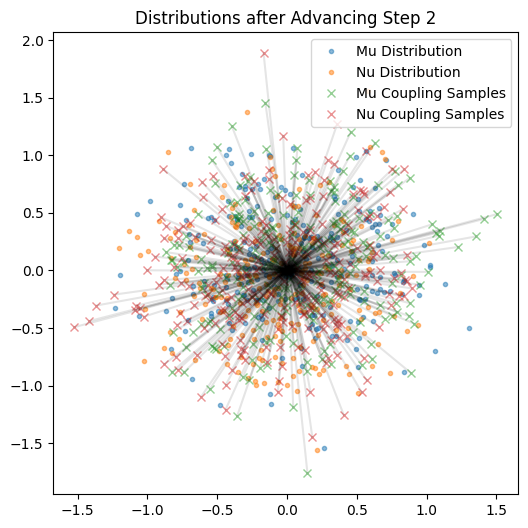

  SW distances — W1_mu=0.0434  W2_mu=0.0492  W1_nu=0.0435  W2_nu=0.0501
Iteration 3/50


Dual Training:   3%|▎         | 3/100 [00:00<00:03, 26.17it/s, Dual Loss=-18]  

Last correction time: 0.0
Current time: 0.04
   f_dual(x0) mean: 0.4182, std: 3.0475
   g_dual(x1) mean: 0.3082, std: 3.0651
   sum mean: 0.7264, std:5.6259, ex: tensor([[  1.2087],
        [ -9.2761],
        [ -7.5763],
        [  4.0579],
        [-11.5454]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 34.69it/s, Dual Loss=-17.8]


   f_dual(x0) mean: -0.0511, std: 3.9479
   g_dual(x1) mean: -0.0471, std: 2.9177
   sum mean: -0.0982, std:5.9715, ex: tensor([[ 11.1202],
        [-10.2026],
        [  3.0002],
        [ -7.6167],
        [  8.1529]], device='cuda:0')


CFM Training:   2%|▏         | 11/500 [00:00<00:05, 97.32it/s, CFM Loss=0.00749]

   Flow model output mean: -0.0770, std: 0.6891


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 114.18it/s, CFM Loss=0.0075] 


   Flow model output mean: -0.0751, std: 0.6908
0.02776987850666046
tensor([[ 0.0532, -0.0013],
        [ 0.0182,  0.0016],
        [ 0.0271, -0.0018],
        [ 0.0343, -0.0030],
        [ 0.0340,  0.0141],
        [ 0.0323,  0.0052],
        [ 0.0203, -0.0006],
        [ 0.0297,  0.0039],
        [ 0.0227,  0.0031],
        [ 0.0244,  0.0028]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 29.10it/s]


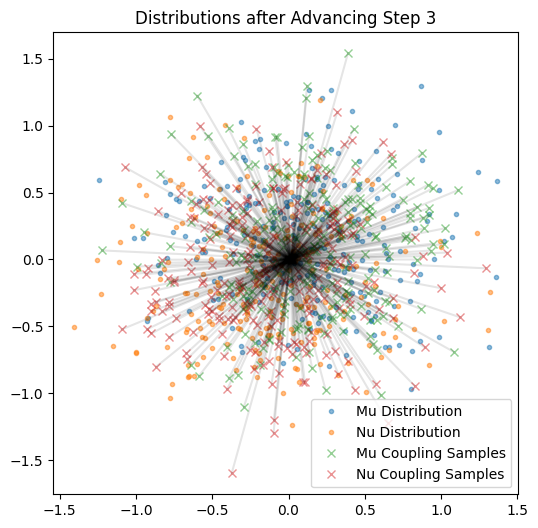

  SW distances — W1_mu=0.0419  W2_mu=0.0493  W1_nu=0.0375  W2_nu=0.0446
Iteration 4/50


Dual Training:   4%|▍         | 4/100 [00:00<00:03, 30.33it/s, Dual Loss=-19.2]

Last correction time: 0.0
Current time: 0.06
   f_dual(x0) mean: 0.4957, std: 3.8252
   g_dual(x1) mean: 0.2196, std: 2.7810
   sum mean: 0.7154, std:5.7327, ex: tensor([[ 1.5182],
        [ 3.0621],
        [ 0.7507],
        [ 4.3098],
        [-0.5156]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 34.31it/s, Dual Loss=-19.1]


   f_dual(x0) mean: 0.1965, std: 4.9370
   g_dual(x1) mean: 0.1151, std: 3.6092
   sum mean: 0.3116, std:6.1124, ex: tensor([[ 4.2795],
        [ 5.3373],
        [-7.1466],
        [-8.5077],
        [11.1821]], device='cuda:0')


CFM Training:   2%|▏         | 12/500 [00:00<00:04, 118.97it/s, CFM Loss=0.00721]

   Flow model output mean: -0.1015, std: 0.6816


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 115.60it/s, CFM Loss=0.00623]


   Flow model output mean: -0.1061, std: 0.6853
0.02107417955994606
tensor([[ 0.0161,  0.0102],
        [ 0.0317, -0.0042],
        [ 0.0099,  0.0063],
        [ 0.0295, -0.0025],
        [ 0.0269,  0.0112],
        [ 0.0193,  0.0085],
        [ 0.0166,  0.0244],
        [ 0.0115,  0.0164],
        [ 0.0039,  0.0038],
        [ 0.0231,  0.0776]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 31.92it/s]


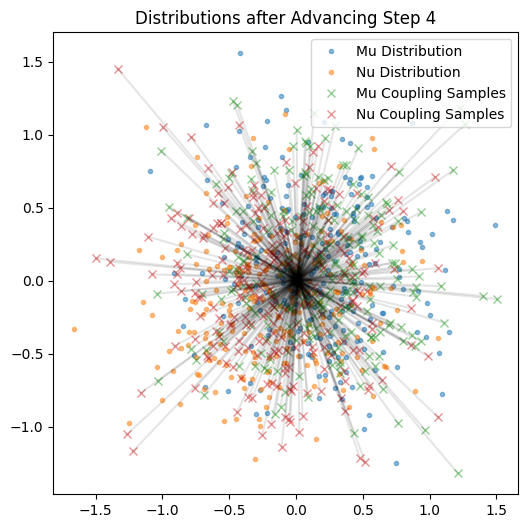

  SW distances — W1_mu=0.0520  W2_mu=0.0585  W1_nu=0.0440  W2_nu=0.0519
Iteration 5/50


Dual Training:   4%|▍         | 4/100 [00:00<00:03, 29.08it/s, Dual Loss=-18.9]

Last correction time: 0.0
Current time: 0.08
   f_dual(x0) mean: 0.5399, std: 4.8508
   g_dual(x1) mean: 0.2851, std: 3.5575
   sum mean: 0.8250, std:5.9180, ex: tensor([[ 4.9114],
        [-5.4529],
        [-7.2933],
        [ 6.0863],
        [-7.5872]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 34.08it/s, Dual Loss=-20.3]


   f_dual(x0) mean: -0.0595, std: 5.0359
   g_dual(x1) mean: 0.0543, std: 3.7893
   sum mean: -0.0053, std:6.1963, ex: tensor([[ -3.1866],
        [-13.4953],
        [  2.1533],
        [ -6.2015],
        [ -8.2609]], device='cuda:0')


CFM Training:   3%|▎         | 14/500 [00:00<00:04, 119.87it/s, CFM Loss=0.00622]

   Flow model output mean: -0.1685, std: 0.6866


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 118.62it/s, CFM Loss=0.007]  


   Flow model output mean: -0.1671, std: 0.6830
0.027929434552788734
tensor([[ 0.0447, -0.0073],
        [ 0.0553, -0.0140],
        [ 0.0107,  0.0003],
        [ 0.0266, -0.0022],
        [ 0.0567, -0.0039],
        [ 0.0427, -0.0193],
        [ 0.0210, -0.0063],
        [ 0.0171, -0.0040],
        [ 0.0171,  0.0122],
        [ 0.0403, -0.0238]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 32.94it/s]


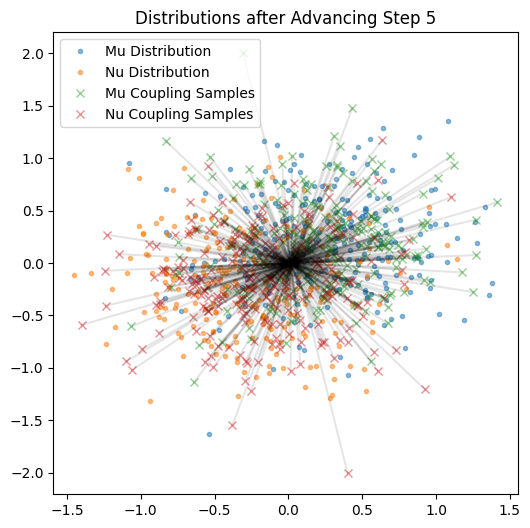

  SW distances — W1_mu=0.0332  W2_mu=0.0406  W1_nu=0.0275  W2_nu=0.0337
Iteration 6/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 33.27it/s, Dual Loss=-19.7]

Last correction time: 0.0
Current time: 0.1
   f_dual(x0) mean: 0.4159, std: 4.9036
   g_dual(x1) mean: 0.4507, std: 3.7343
   sum mean: 0.8666, std:5.9922, ex: tensor([[ 5.3924],
        [ 5.0146],
        [ 3.9459],
        [-6.8567],
        [ 1.5885]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 37.00it/s, Dual Loss=-20.4]


   f_dual(x0) mean: -0.1338, std: 3.2108
   g_dual(x1) mean: -0.1117, std: 3.1860
   sum mean: -0.2454, std:6.2579, ex: tensor([[-4.6405],
        [-6.2948],
        [ 0.2138],
        [ 3.8321],
        [ 2.0525]], device='cuda:0')


CFM Training:   3%|▎         | 14/500 [00:00<00:03, 124.51it/s, CFM Loss=0.00815]

   Flow model output mean: -0.1951, std: 0.6746


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 119.61it/s, CFM Loss=0.00679]


   Flow model output mean: -0.1895, std: 0.6697
0.03423258662223816
tensor([[ 0.0457,  0.0019],
        [ 0.0331, -0.0065],
        [ 0.0421,  0.0414],
        [ 0.0233,  0.0221],
        [ 0.0229,  0.0162],
        [ 0.0385,  0.0010],
        [ 0.0144,  0.0092],
        [ 0.0290,  0.0160],
        [ 0.0441,  0.0035],
        [ 0.0277,  0.0113]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.78it/s]


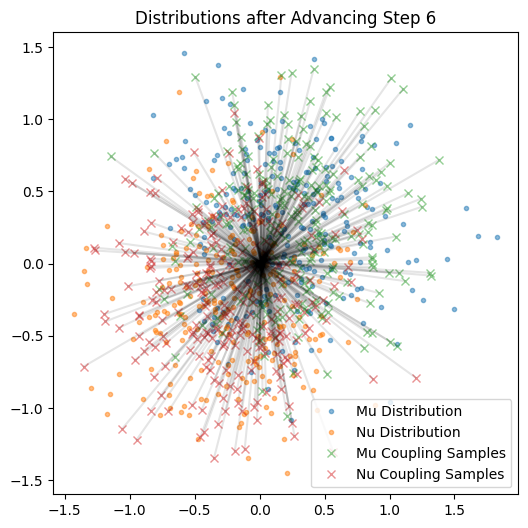

  SW distances — W1_mu=0.0212  W2_mu=0.0282  W1_nu=0.0226  W2_nu=0.0300
Iteration 7/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 33.35it/s, Dual Loss=-21.4]

Last correction time: 0.0
Current time: 0.12
   f_dual(x0) mean: 0.2543, std: 3.1673
   g_dual(x1) mean: 0.1945, std: 3.0552
   sum mean: 0.4488, std:6.0784, ex: tensor([[ -5.3284],
        [ -2.9257],
        [  9.8913],
        [ -2.5368],
        [-15.5284]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 35.15it/s, Dual Loss=-22.3]


   f_dual(x0) mean: 0.0619, std: 1.2169
   g_dual(x1) mean: 0.0690, std: 6.1913
   sum mean: 0.1309, std:6.2891, ex: tensor([[  7.9692],
        [-14.8963],
        [ -0.9945],
        [  1.6624],
        [  4.7915]], device='cuda:0')


CFM Training:   3%|▎         | 15/500 [00:00<00:03, 126.05it/s, CFM Loss=0.00756]

   Flow model output mean: -0.2357, std: 0.6769


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 120.46it/s, CFM Loss=0.00701]


   Flow model output mean: -0.2482, std: 0.6803
0.0184322502464056
tensor([[-0.0014, -0.0198],
        [ 0.0025,  0.0007],
        [ 0.0257, -0.0136],
        [ 0.0097,  0.0061],
        [ 0.0221, -0.0074],
        [ 0.0129,  0.0116],
        [ 0.0152, -0.0110],
        [ 0.0083,  0.0107],
        [ 0.0191,  0.0020],
        [ 0.0019,  0.0060]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 32.63it/s]


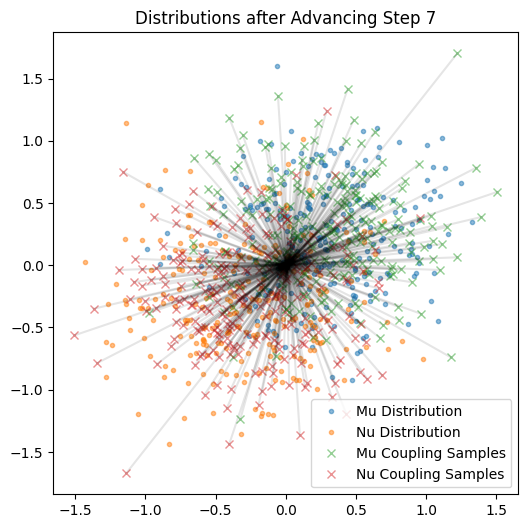

  SW distances — W1_mu=0.0315  W2_mu=0.0383  W1_nu=0.0363  W2_nu=0.0442
Iteration 8/50


Dual Training:   3%|▎         | 3/100 [00:00<00:03, 29.38it/s, Dual Loss=-22.7]

Last correction time: 0.0
Current time: 0.14
   f_dual(x0) mean: 0.0770, std: 1.2004
   g_dual(x1) mean: 0.9850, std: 6.1580
   sum mean: 1.0620, std:6.2435, ex: tensor([[-8.4152],
        [-7.9183],
        [ 1.5911],
        [ 9.1280],
        [13.2992]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.79it/s, Dual Loss=-23.5]


   f_dual(x0) mean: -0.1872, std: 3.4308
   g_dual(x1) mean: 0.0295, std: 8.9375
   sum mean: -0.1577, std:6.4574, ex: tensor([[-0.7654],
        [-8.9456],
        [-0.4536],
        [ 7.9535],
        [ 4.2864]], device='cuda:0')


CFM Training:   2%|▏         | 12/500 [00:00<00:04, 117.84it/s, CFM Loss=0.00819]

   Flow model output mean: -0.2802, std: 0.6773


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 119.28it/s, CFM Loss=0.00851]


   Flow model output mean: -0.2690, std: 0.6710
0.030643945559859276
tensor([[ 0.0038,  0.0410],
        [-0.0084,  0.0175],
        [-0.0158,  0.0303],
        [ 0.0126,  0.0087],
        [ 0.0211,  0.0452],
        [ 0.0090,  0.0339],
        [ 0.0064,  0.0106],
        [ 0.0009,  0.0191],
        [ 0.0103,  0.0028],
        [-0.0127,  0.0275]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 31.42it/s]


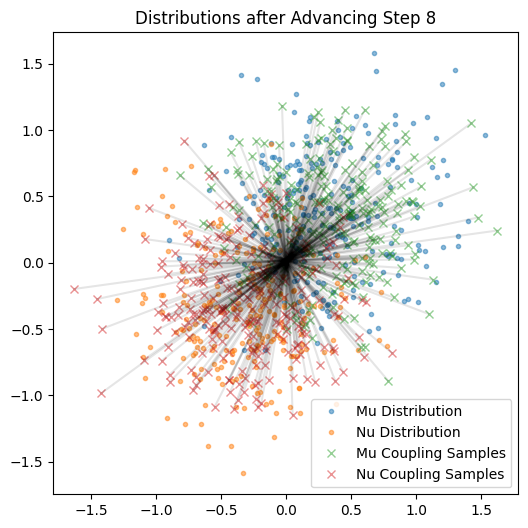

  SW distances — W1_mu=0.0383  W2_mu=0.0442  W1_nu=0.0290  W2_nu=0.0367
Iteration 9/50


Dual Training:   3%|▎         | 3/100 [00:00<00:03, 27.84it/s, Dual Loss=-24.5]

Last correction time: 0.0
Current time: 0.16
   f_dual(x0) mean: -0.5102, std: 3.4100
   g_dual(x1) mean: 0.9733, std: 8.7085
   sum mean: 0.4632, std:6.1571, ex: tensor([[-10.1155],
        [  4.2051],
        [  7.3046],
        [ -1.8268],
        [  4.4187]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.74it/s, Dual Loss=-26.5]


   f_dual(x0) mean: -0.3826, std: 8.7446
   g_dual(x1) mean: 0.5136, std: 13.6126
   sum mean: 0.1311, std:7.2101, ex: tensor([[ 8.7089],
        [ 8.6575],
        [ 8.0899],
        [-8.0230],
        [-8.4836]], device='cuda:0')


CFM Training:   3%|▎         | 13/500 [00:00<00:03, 127.00it/s, CFM Loss=0.00784]

   Flow model output mean: -0.3125, std: 0.6823


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 119.73it/s, CFM Loss=0.00713]


   Flow model output mean: -0.3209, std: 0.6879
0.0255446620285511
tensor([[ 0.0057,  0.0299],
        [ 0.0190,  0.0005],
        [-0.0116,  0.0165],
        [-0.0061,  0.0095],
        [-0.0017,  0.0166],
        [ 0.0054,  0.0342],
        [ 0.0131,  0.0447],
        [ 0.0165,  0.0049],
        [ 0.0134,  0.0105],
        [ 0.0364,  0.0053]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 31.44it/s]


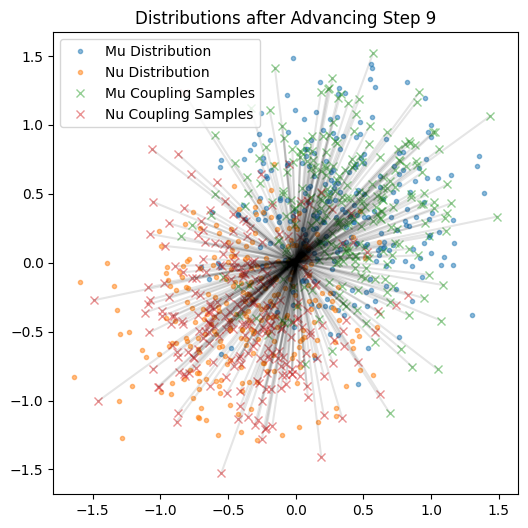

  SW distances — W1_mu=0.0381  W2_mu=0.0452  W1_nu=0.0252  W2_nu=0.0321
Iteration 10/50
Running correction step at iteration 10
bridge_model weights before correction:
  model.net.0.weight: 0.010557523928582668


Correct Marginal Flow Matching: 100%|██████████| 2000/2000 [00:34<00:00, 57.39it/s, Correction Loss=0.534]


bridge_model weights after correction:
  model.net.0.weight: 0.01215475331991911
0.99
tensor([-2.0389, -1.9758], device='cuda:0') tensor([-2.0141, -2.0033], device='cuda:0')


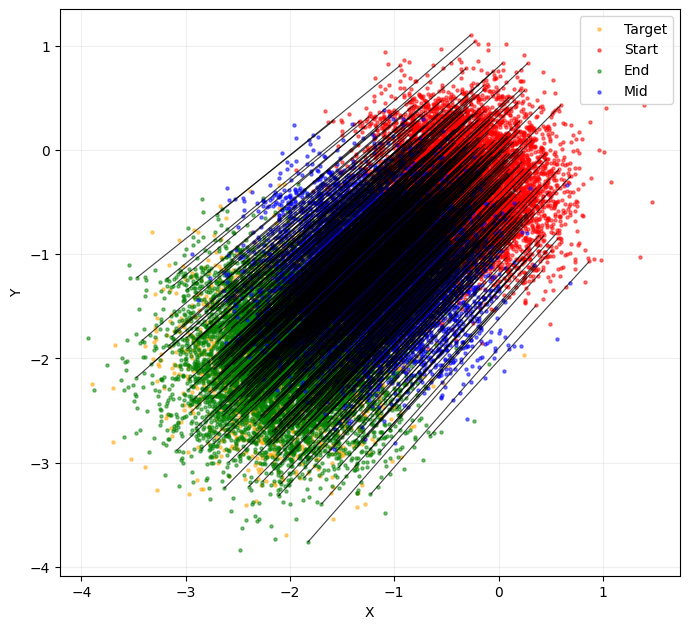

Dual Training:   4%|▍         | 4/100 [00:00<00:02, 33.86it/s, Dual Loss=-25.6]

Last correction time: 0.18
Current time: 0.18
   f_dual(x0) mean: -0.9344, std: 8.5008
   g_dual(x1) mean: 2.3704, std: 13.0931
   sum mean: 1.4361, std:6.8482, ex: tensor([[ 8.3778],
        [-6.1090],
        [ 7.0579],
        [-1.6917],
        [ 4.7956]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 37.05it/s, Dual Loss=-26.8]


   f_dual(x0) mean: 0.0456, std: 4.3776
   g_dual(x1) mean: 0.0840, std: 10.4302
   sum mean: 0.1295, std:7.0367, ex: tensor([[ -4.9309],
        [ 11.2072],
        [ -2.9468],
        [  3.9704],
        [-22.9236]], device='cuda:0')


CFM Training:   2%|▏         | 10/500 [00:00<00:04, 99.30it/s, CFM Loss=0.00702]

   Flow model output mean: -0.3641, std: 0.6980


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 117.87it/s, CFM Loss=0.00767]


   Flow model output mean: -0.3750, std: 0.7036
0.01776164397597313
tensor([[ 0.0148, -0.0106],
        [-0.0023, -0.0040],
        [-0.0026,  0.0152],
        [-0.0080, -0.0060],
        [ 0.0049, -0.0014],
        [-0.0060,  0.0077],
        [ 0.0116, -0.0122],
        [-0.0129,  0.0042],
        [ 0.0053, -0.0028],
        [-0.0019, -0.0017]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 32.29it/s]


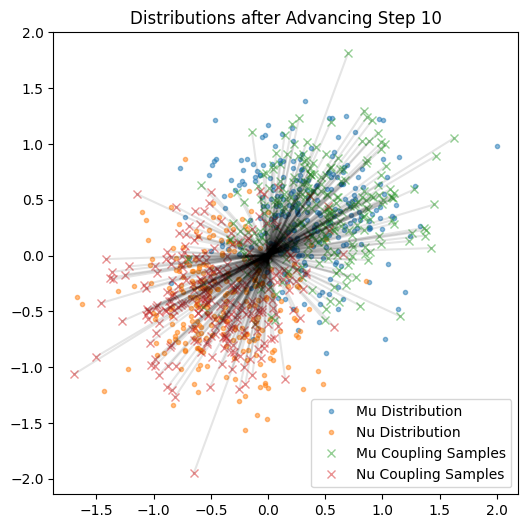

  SW distances — W1_mu=0.0422  W2_mu=0.0511  W1_nu=0.0431  W2_nu=0.0518
Iteration 11/50
Increasing dual training epochs for correction fitting.


Dual Training:   1%|          | 4/500 [00:00<00:14, 34.21it/s, Dual Loss=-25.5]

Last correction time: 0.18
Current time: 0.2
   f_dual(x0) mean: -0.3058, std: 4.3624
   g_dual(x1) mean: 1.8763, std: 10.3213
   sum mean: 1.5705, std:6.9811, ex: tensor([[  2.0656],
        [  6.2538],
        [  5.1716],
        [-10.0755],
        [  2.1431]], device='cuda:0')


Dual Training: 100%|██████████| 500/500 [00:13<00:00, 36.49it/s, Dual Loss=-25.9]


   f_dual(x0) mean: -0.0875, std: 4.6451
   g_dual(x1) mean: 0.1084, std: 11.3188
   sum mean: 0.0208, std:7.0817, ex: tensor([[4.0494],
        [0.4548],
        [3.5502],
        [6.3235],
        [3.6221]], device='cuda:0')
Increasing dual training epochs for correction fitting.


CFM Training:   0%|          | 12/2500 [00:00<00:21, 117.71it/s, CFM Loss=0.00831]

   Flow model output mean: -0.4096, std: 0.7127


CFM Training: 100%|██████████| 2500/2500 [00:23<00:00, 104.33it/s, CFM Loss=0.0052] 


   Flow model output mean: -0.4121, std: 0.7178


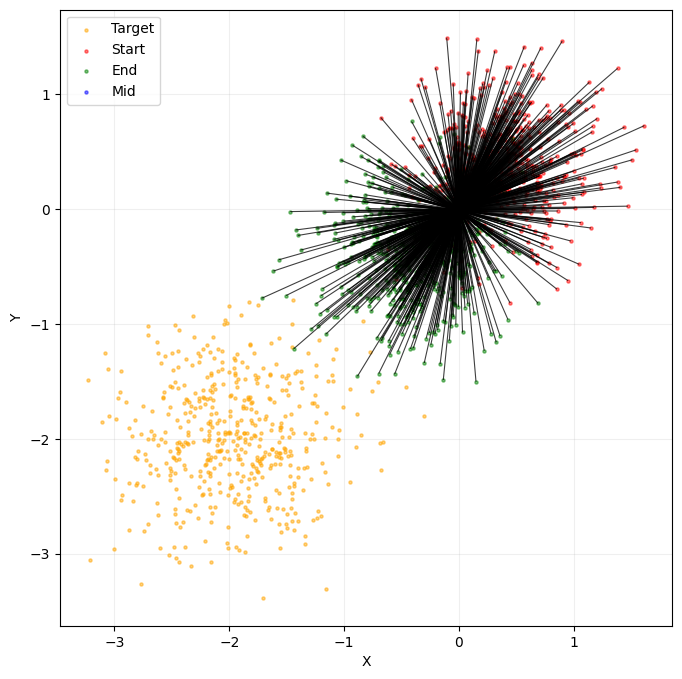

0.024278340861201286
tensor([[-0.0092, -0.0160],
        [-0.0406, -0.0161],
        [-0.0147, -0.0097],
        [-0.0361, -0.0097],
        [-0.0087, -0.0142],
        [-0.0014, -0.0391],
        [ 0.0020, -0.0164],
        [-0.0055, -0.0369],
        [-0.0083,  0.0104],
        [-0.0368, -0.0057]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.08it/s]


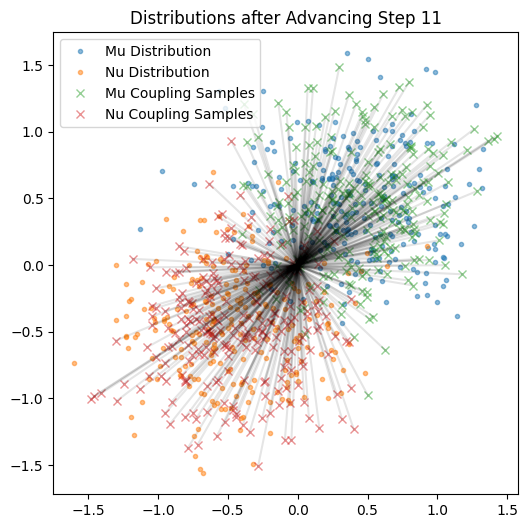

  SW distances — W1_mu=0.0508  W2_mu=0.0570  W1_nu=0.0494  W2_nu=0.0655
Iteration 12/50


Dual Training:   3%|▎         | 3/100 [00:00<00:03, 29.31it/s, Dual Loss=-25.7]

Last correction time: 0.18
Current time: 0.22
   f_dual(x0) mean: -0.7662, std: 4.7121
   g_dual(x1) mean: 2.3124, std: 11.3058
   sum mean: 1.5462, std:7.0430, ex: tensor([[ 1.5636],
        [ 5.6776],
        [-3.5736],
        [-2.3259],
        [-0.7010]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.43it/s, Dual Loss=-26.6]


   f_dual(x0) mean: -0.1311, std: 4.4658
   g_dual(x1) mean: 0.2407, std: 11.1323
   sum mean: 0.1096, std:7.1830, ex: tensor([[-3.3667],
        [-4.4865],
        [-0.4253],
        [ 3.0298],
        [ 5.3622]], device='cuda:0')


CFM Training:   2%|▏         | 10/500 [00:00<00:05, 97.78it/s, CFM Loss=0.006]  

   Flow model output mean: -0.4590, std: 0.7374


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 117.14it/s, CFM Loss=0.00668]


   Flow model output mean: -0.4599, std: 0.7376
0.027186693623661995
tensor([[-0.0338, -0.0116],
        [ 0.0161,  0.0141],
        [-0.0473, -0.0207],
        [-0.0143,  0.0009],
        [-0.0393, -0.0140],
        [-0.0073, -0.0133],
        [-0.0085, -0.0149],
        [-0.0227, -0.0214],
        [-0.0126, -0.0031],
        [-0.0232,  0.0006]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.48it/s]


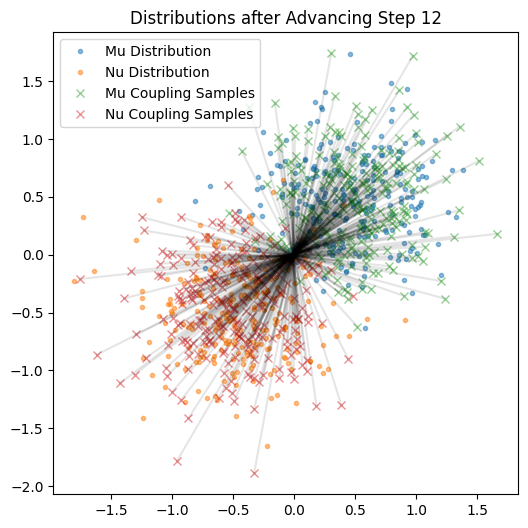

  SW distances — W1_mu=0.0315  W2_mu=0.0375  W1_nu=0.0419  W2_nu=0.0506
Iteration 13/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 33.97it/s, Dual Loss=-26.5]

Last correction time: 0.18
Current time: 0.24
   f_dual(x0) mean: -0.5669, std: 4.5051
   g_dual(x1) mean: 1.7196, std: 10.9086
   sum mean: 1.1527, std:6.8976, ex: tensor([[ 4.9096],
        [-1.2656],
        [13.4585],
        [ 4.3038],
        [-5.3423]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.12it/s, Dual Loss=-26.7]


   f_dual(x0) mean: 0.2409, std: 4.7103
   g_dual(x1) mean: -0.0909, std: 10.9797
   sum mean: 0.1500, std:7.2124, ex: tensor([[ -7.8508],
        [  1.2022],
        [-13.0912],
        [  2.1007],
        [  6.4285]], device='cuda:0')


CFM Training:   2%|▏         | 9/500 [00:00<00:05, 84.39it/s, CFM Loss=0.00695]

   Flow model output mean: -0.5034, std: 0.7548


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 113.12it/s, CFM Loss=0.00754]


   Flow model output mean: -0.5091, std: 0.7586
0.03580693155527115
tensor([[-0.0509, -0.0084],
        [-0.0802, -0.0185],
        [-0.0002, -0.0059],
        [-0.0434,  0.0017],
        [-0.0251,  0.0052],
        [-0.0334,  0.0217],
        [-0.0208,  0.0035],
        [-0.0632, -0.0178],
        [-0.0101,  0.0017],
        [-0.0270, -0.0078]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 31.85it/s]


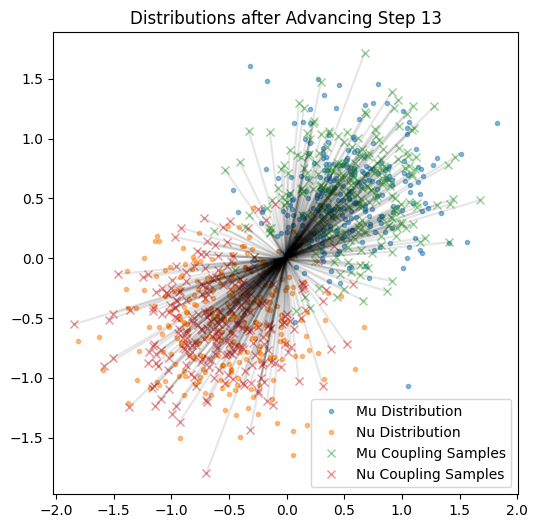

  SW distances — W1_mu=0.0509  W2_mu=0.0576  W1_nu=0.0697  W2_nu=0.0785
Iteration 14/50


Dual Training:   4%|▍         | 4/100 [00:00<00:03, 28.77it/s, Dual Loss=-27.6]

Last correction time: 0.18
Current time: 0.26
   f_dual(x0) mean: -0.3182, std: 4.7533
   g_dual(x1) mean: 1.6221, std: 10.7713
   sum mean: 1.3038, std:6.9603, ex: tensor([[ 1.0788],
        [ 2.2477],
        [-8.4559],
        [ 0.7170],
        [-1.3223]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 34.37it/s, Dual Loss=-28] 


   f_dual(x0) mean: 0.1881, std: 5.6162
   g_dual(x1) mean: -0.4418, std: 11.1477
   sum mean: -0.2537, std:7.3311, ex: tensor([[ -7.2312],
        [ 10.3937],
        [  1.4429],
        [-11.4120],
        [ -2.6628]], device='cuda:0')


CFM Training:   3%|▎         | 13/500 [00:00<00:03, 124.88it/s, CFM Loss=0.00774]

   Flow model output mean: -0.5430, std: 0.7808


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 117.19it/s, CFM Loss=0.00726]


   Flow model output mean: -0.5232, std: 0.7682
0.02832227200269699
tensor([[ 0.0094,  0.0168],
        [-0.0141,  0.0157],
        [-0.0178,  0.0223],
        [-0.0199,  0.0139],
        [-0.0244, -0.0078],
        [-0.0020, -0.0142],
        [-0.0104, -0.0017],
        [-0.0352, -0.0030],
        [-0.0240, -0.0079],
        [-0.0436, -0.0091]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.36it/s]


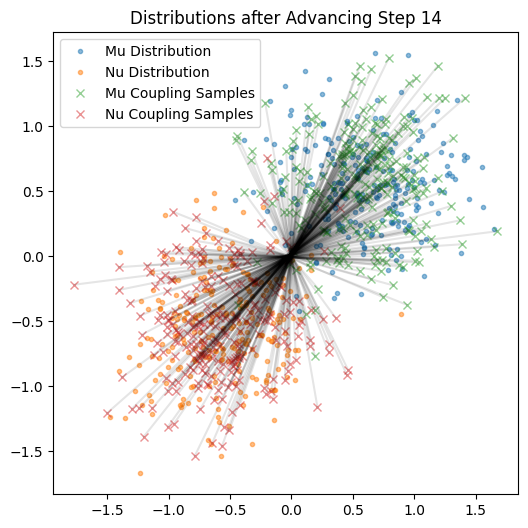

  SW distances — W1_mu=0.0306  W2_mu=0.0386  W1_nu=0.0413  W2_nu=0.0511
Iteration 15/50


Dual Training:   4%|▍         | 4/100 [00:00<00:03, 28.78it/s, Dual Loss=-30.9]

Last correction time: 0.18
Current time: 0.28
   f_dual(x0) mean: -0.3882, std: 5.5146
   g_dual(x1) mean: 0.8074, std: 10.7313
   sum mean: 0.4192, std:6.9356, ex: tensor([[-6.2098],
        [ 5.0079],
        [ 4.2289],
        [ 2.9791],
        [-2.2165]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.12it/s, Dual Loss=-30.1]


   f_dual(x0) mean: 0.3755, std: 6.4925
   g_dual(x1) mean: 0.1054, std: 11.9090
   sum mean: 0.4809, std:7.4653, ex: tensor([[ 3.1690],
        [-8.9247],
        [-9.1975],
        [-3.2589],
        [ 8.4406]], device='cuda:0')


CFM Training:   2%|▏         | 9/500 [00:00<00:05, 88.91it/s, CFM Loss=0.00766]

   Flow model output mean: -0.5625, std: 0.7918


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 119.07it/s, CFM Loss=0.00552]


   Flow model output mean: -0.5724, std: 0.7963
0.03206612914800644
tensor([[-0.0197,  0.0296],
        [-0.0353,  0.0504],
        [-0.0202,  0.0300],
        [-0.0228,  0.0218],
        [-0.0491, -0.0025],
        [-0.0072,  0.0293],
        [-0.0175,  0.0078],
        [-0.0681, -0.0101],
        [ 0.0412, -0.0268],
        [-0.0263,  0.0050]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.79it/s]


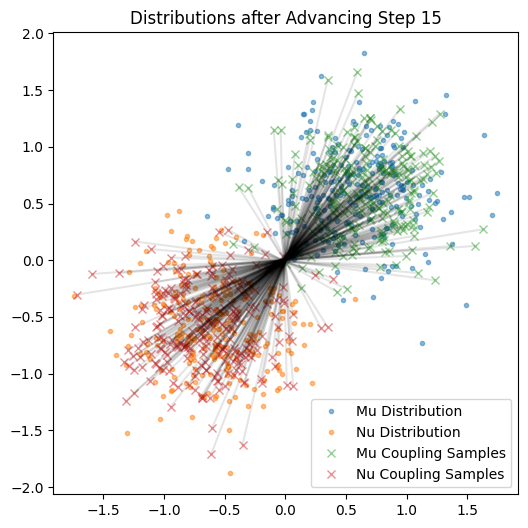

  SW distances — W1_mu=0.0365  W2_mu=0.0422  W1_nu=0.0497  W2_nu=0.0583
Iteration 16/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 33.60it/s, Dual Loss=-30.9]

Last correction time: 0.18
Current time: 0.3
   f_dual(x0) mean: -0.1420, std: 6.3723
   g_dual(x1) mean: 1.7234, std: 11.5292
   sum mean: 1.5814, std:7.1533, ex: tensor([[ 7.1607],
        [ 8.5592],
        [13.2358],
        [-9.2157],
        [13.1197]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 35.11it/s, Dual Loss=-30.9]


   f_dual(x0) mean: 0.0753, std: 7.3941
   g_dual(x1) mean: -0.2620, std: 12.9837
   sum mean: -0.1867, std:7.8402, ex: tensor([[  0.5229],
        [-13.4655],
        [  6.1287],
        [ -0.9970],
        [  4.5791]], device='cuda:0')


CFM Training:   2%|▏         | 9/500 [00:00<00:05, 85.26it/s, CFM Loss=0.00707]

   Flow model output mean: -0.6062, std: 0.8143


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 119.27it/s, CFM Loss=0.00668]


   Flow model output mean: -0.6139, std: 0.8163
0.0394374281167984
tensor([[-0.0244,  0.0490],
        [-0.0253,  0.0339],
        [-0.0324,  0.0228],
        [-0.0297,  0.0291],
        [-0.1037, -0.0314],
        [-0.0421, -0.0001],
        [-0.0542,  0.0484],
        [ 0.0012,  0.0169],
        [-0.0215,  0.0035],
        [ 0.0279, -0.0160]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 31.81it/s]


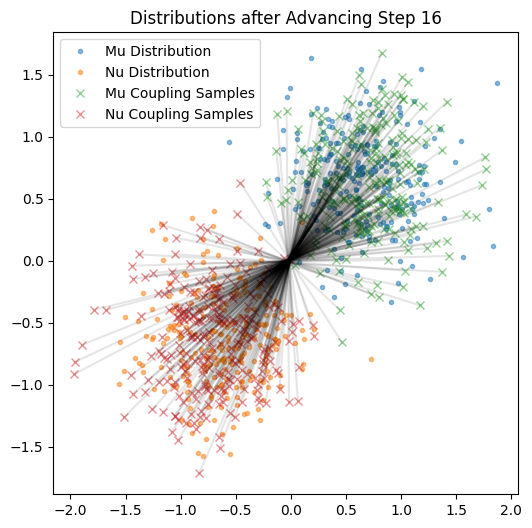

  SW distances — W1_mu=0.0295  W2_mu=0.0359  W1_nu=0.0499  W2_nu=0.0571
Iteration 17/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 36.33it/s, Dual Loss=-31.8]

Last correction time: 0.18
Current time: 0.32
   f_dual(x0) mean: -0.3669, std: 7.3768
   g_dual(x1) mean: 1.5186, std: 12.6717
   sum mean: 1.1516, std:7.4368, ex: tensor([[-4.8427],
        [ 3.9342],
        [-3.8102],
        [-6.3249],
        [-4.6798]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.24it/s, Dual Loss=-32.7]


   f_dual(x0) mean: 0.0402, std: 8.5280
   g_dual(x1) mean: 0.0290, std: 13.5512
   sum mean: 0.0692, std:7.7202, ex: tensor([[ -9.2500],
        [  0.6780],
        [ -4.0249],
        [-13.0372],
        [-12.7991]], device='cuda:0')


CFM Training:   2%|▏         | 9/500 [00:00<00:05, 89.86it/s, CFM Loss=0.00604]

   Flow model output mean: -0.6494, std: 0.8361


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 113.19it/s, CFM Loss=0.00707]


   Flow model output mean: -0.6408, std: 0.8298
0.03655603528022766
tensor([[-0.0188,  0.0231],
        [ 0.0157,  0.0406],
        [-0.0088,  0.0136],
        [-0.0313,  0.0045],
        [-0.0246,  0.0214],
        [-0.0021,  0.0337],
        [-0.0185,  0.0302],
        [-0.0283,  0.0131],
        [-0.0099,  0.0374],
        [-0.0286,  0.0160]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 30.38it/s]


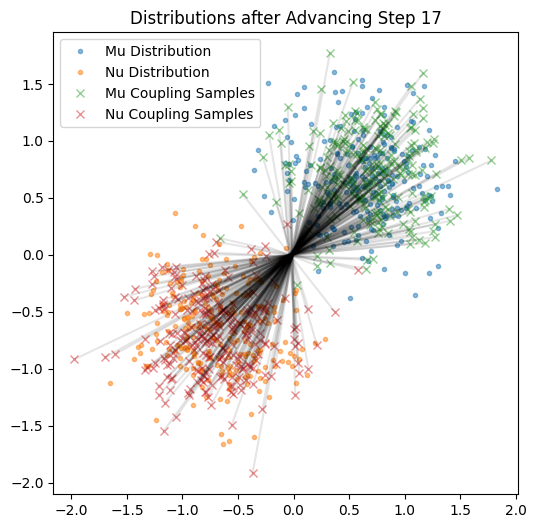

  SW distances — W1_mu=0.0455  W2_mu=0.0513  W1_nu=0.0347  W2_nu=0.0426
Iteration 18/50


Dual Training:   3%|▎         | 3/100 [00:00<00:03, 29.57it/s, Dual Loss=-33.9]

Last correction time: 0.18
Current time: 0.34
   f_dual(x0) mean: -0.5124, std: 8.4772
   g_dual(x1) mean: 1.5925, std: 13.1550
   sum mean: 1.0801, std:7.4131, ex: tensor([[ -2.7750],
        [-12.8321],
        [ -1.3158],
        [-12.6367],
        [ -0.4812]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.87it/s, Dual Loss=-34.4]


   f_dual(x0) mean: -0.0996, std: 8.8731
   g_dual(x1) mean: 0.4835, std: 13.9765
   sum mean: 0.3839, std:7.8850, ex: tensor([[-1.4600],
        [ 2.9712],
        [-2.0385],
        [13.7802],
        [ 5.2553]], device='cuda:0')


CFM Training:   2%|▏         | 9/500 [00:00<00:05, 87.68it/s, CFM Loss=0.00724]

   Flow model output mean: -0.6847, std: 0.8624


CFM Training: 100%|██████████| 500/500 [00:04<00:00, 114.08it/s, CFM Loss=0.00514]


   Flow model output mean: -0.7004, std: 0.8786
0.04227841645479202
tensor([[-0.1055, -0.0798],
        [-0.0444, -0.0146],
        [-0.0460, -0.0181],
        [-0.0284,  0.0082],
        [-0.0335, -0.0168],
        [-0.0157, -0.0213],
        [-0.0366, -0.0050],
        [-0.0652, -0.0156],
        [-0.0248, -0.0128],
        [-0.0870, -0.0549]])


Advancing coupling: 100%|██████████| 25/25 [00:00<00:00, 33.03it/s]


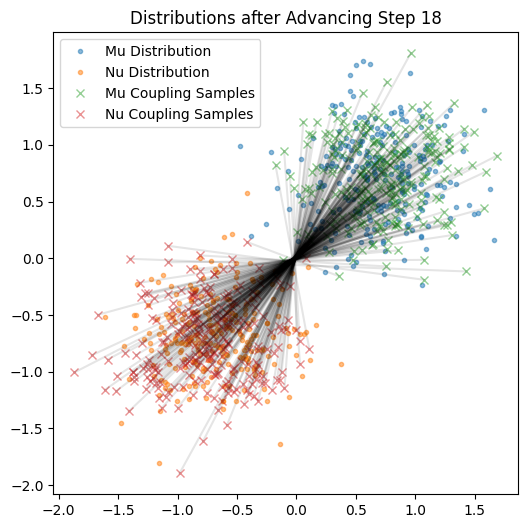

  SW distances — W1_mu=0.0364  W2_mu=0.0417  W1_nu=0.0526  W2_nu=0.0631
Iteration 19/50


Dual Training:   4%|▍         | 4/100 [00:00<00:02, 35.07it/s, Dual Loss=-29.8]

Last correction time: 0.18
Current time: 0.36
   f_dual(x0) mean: -0.6668, std: 8.9263
   g_dual(x1) mean: 2.9700, std: 14.0441
   sum mean: 2.3032, std:7.7589, ex: tensor([[ 9.6414],
        [-4.3554],
        [12.0949],
        [-0.2838],
        [12.4243]], device='cuda:0')


Dual Training: 100%|██████████| 100/100 [00:02<00:00, 36.45it/s, Dual Loss=-32.2]


   f_dual(x0) mean: -0.0595, std: 8.7720
   g_dual(x1) mean: -0.4433, std: 13.3345
   sum mean: -0.5028, std:7.6826, ex: tensor([[  6.1595],
        [  6.1538],
        [ -1.8159],
        [  0.2993],
        [-14.2708]], device='cuda:0')


CFM Training:   2%|▏         | 11/500 [00:00<00:04, 109.97it/s, CFM Loss=0.00724]

   Flow model output mean: -0.7422, std: 0.9214


CFM Training:  71%|███████   | 354/500 [00:03<00:01, 96.85it/s, CFM Loss=0.00615] 

In [ ]:
trainer.train(retrain=False, save='experiments/test_simple_bi')#flip_perturbation2/')

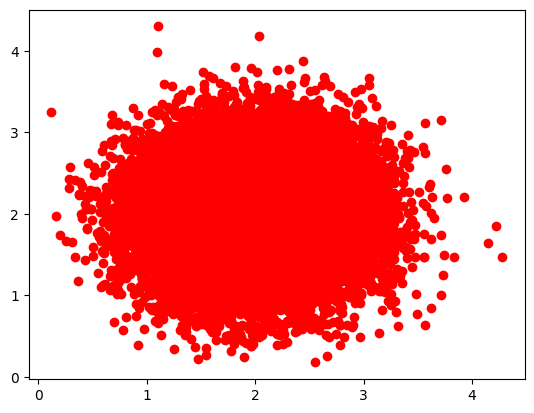

Mean of y in x dimension: -2.4126617908477783, Mean of y in y dimension: -2.2311103343963623
Mean of y_target in x dimension: -1.9976015090942383, Mean of y in y dimension: -2.0032169818878174
Mean of y_coupling in x dimension: -2.404113292694092, Mean of y in y dimension: -2.228447437286377
Mean of y_transport in x dimension: -1.998451590538025, Mean of y in y dimension: -1.997588872909546)
Mean of y_transport_2 in x dimension: -1.9995862245559692, Mean of y in y dimension: -2.005648374557495)


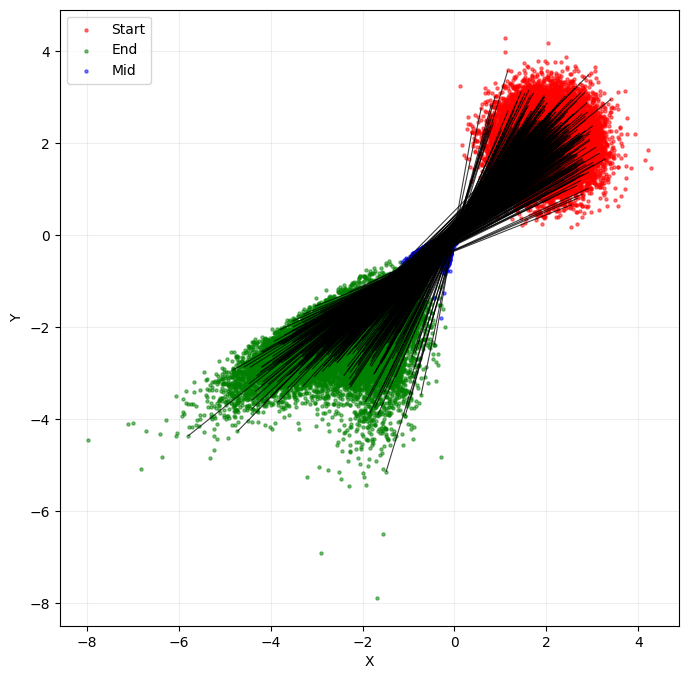

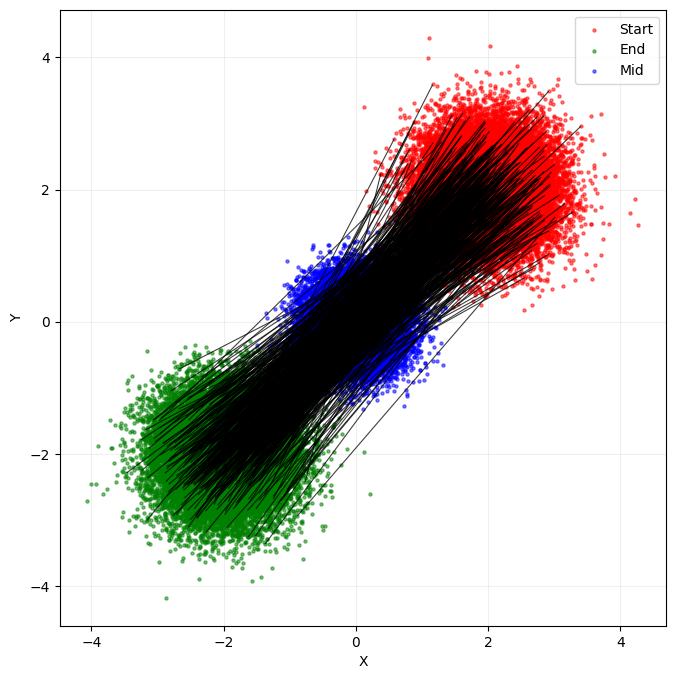

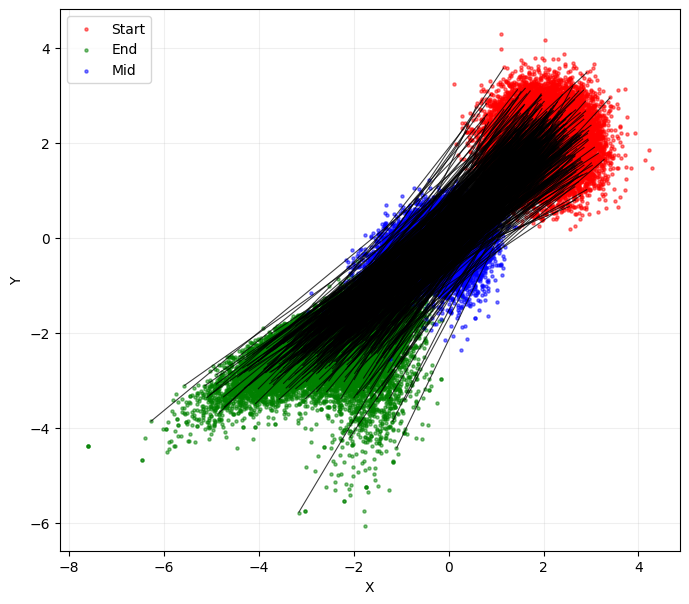

In [ ]:
import matplotlib.pyplot as plt
n_samples = 25000
x = new_source.sample(n_samples).to(trainer.device)
# x = trainer.current_coupling.sample_init(n_samples).to(trainer.device)
y = trainer.flow_matching.evolve(
    x,
    trainer.strategy.forward_model,
    num_steps=100,
    sigma=0.0,
    extend=True,
)[:, :2]

plt.scatter(x[:, 0].cpu(), x[:, 1].cpu(), color='red')
# plt.scatter(x_2[:, 0].cpu(), x_2[:, 1].cpu(), color='blue')
plt.show()

# Print mean of y in x and y dimensions
y_target = new_target.sample(n_samples).to(trainer.device)
_, y_coupling = trainer.current_coupling.coupling_sample(n_samples)
print(f"Mean of y in x dimension: {y[:, 0].mean().item()}, Mean of y in y dimension: {y[:, 1].mean().item()}")
print(f"Mean of y_target in x dimension: {y_target[:, 0].mean().item()}, Mean of y in y dimension: {y_target[:, 1].mean().item()}")
print(f"Mean of y_coupling in x dimension: {y_coupling[:, 0].mean().item()}, Mean of y in y dimension: {y_coupling[:, 1].mean().item()}")
y_transport = new_transport_map(new_source.sample(n_samples).cpu())
print(f"Mean of y_transport in x dimension: {y_transport[:, 0].mean().item()}, Mean of y in y dimension: {y_transport[:, 1].mean().item()})")
y_transport_2 = new_transport_map(x.cpu())
print(f"Mean of y_transport_2 in x dimension: {y_transport_2[:, 0].mean().item()}, Mean of y in y dimension: {y_transport_2[:, 1].mean().item()})")

trainer.visualizer._display_evolution(x.cpu(), y.cpu())
plt.show()
trainer.visualizer._display_evolution(x.cpu(), y_target.cpu())
plt.show()
trainer.visualizer._display_evolution(x.cpu(), y_coupling.cpu())
plt.show()

In [ ]:
# Save models in trainer.strategy
# trainer.strategy.forward_model
torch.save(trainer.strategy.forward_model.state_dict(), 'experiments/flip_perturbation2/final_forward_model.pth')
torch.save(trainer.strategy.backward_model.state_dict(), 'experiments/flip_perturbation2/final_backward_model.pth')

AttributeError: 'Strategy' object has no attribute 'backward_model'

In [ ]:
import matplotlib.pyplot as plt
n_samples = 6
x = trainer.new_source.sample(n_samples)
# y_target = x.flip(dims=[2])

angle = 10  # degrees
rotation = T.RandomRotation((angle, angle), fill=(-1,))
y_target = torch.flip(x, dims=[2])
y_target = rotation(y_target)

x, y_target = x.to(trainer.device), y_target.to(trainer.device)

x, y_target = trainer.current_coupling.coupling_sample(n_samples)
x, y_target = x.to(trainer.device), y_target.to(trainer.device)

y = trainer.flow_matching.evolve(
    x,
    trainer.strategy.forward_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y = y[:, :1, :, :]

y = torch.flip(x, dims=[2])
y = rotation(y)
trainer.visualizer._display_evolution(x.cpu(), y.cpu(), y_target.cpu())
plt.show()

# Print the average error between the evolved samples and the target
error = torch.mean(torch.abs(y - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

initial_model = trainer.strategy.initial_forward_model
state_dict = torch.load('experiments/flip_perturbation2/initial_forward_model.pth', map_location=trainer.device)
initial_model.load_state_dict(state_dict)
n_samples = 6
y_init = trainer.flow_matching.evolve(
    x,
    initial_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y_init = y_init[:, :1, :, :]
trainer.visualizer._display_evolution(x.cpu(), y_init.cpu(), y_target.cpu())
plt.show()


error = torch.mean(torch.abs(y_init - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

plt.figure(figsize=(12, 6))
for i in range(n_samples):
    plt.subplot(3, n_samples, i + 1)
    plt.imshow(y_target[i, 0].cpu() - y[i, 0].cpu(), cmap='gray')
    plt.title('Source')
    plt.axis('off')

    plt.subplot(3, n_samples, n_samples + i + 1)
    plt.imshow(y_target[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
    plt.title('Target - Evolved')
    plt.axis('off')

    plt.subplot(3, n_samples, 2 * n_samples + i + 1)
    plt.imshow(y[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
    plt.title('Target - Evolved')
    plt.axis('off')
plt.show()

# Print weights of the first layer of the forward model
first_layer_weights = trainer.strategy.forward_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

first_layer_weights = initial_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

# unet_wrapper(
#   (model): UNetModelWrapper(
#     (time_embed): Sequential(
#       (0): Linear(in_features=32, out_features=128, bias=True)
#       (1): SiLU()
#       (2): Linear(in_features=128, out_features=128, bias=True)
#     )
#     (input_blocks): ModuleList(
#       (0): TimestepEmbedSequential(
#         (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#       )
#       (1): TimestepEmbedSequential(
#         (0): ResBlock(
#           (in_layers): Sequential(
#             (0): GroupNorm32(32, 32, eps=1e-05, affine=True)
#             (1): SiLU()
#             (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#           )

IndexError: Dimension out of range (expected to be in range of [-2, 1], but got 2)

In [ ]:
import matplotlib.pyplot as plt
trainer.visualizer.display(10, trainer)
plt.show()

trainer.visualizer.display(11, trainer)
plt.show()